# Regions as islands

A nest shrinks one sample, so the areas it measures are arbitrary: hulls of whichever points remain. `designs.islands` does the other thing: you choose the regions (states, counties, parks, real islands), and each is one row of area and species. That is species-area data of the island type, from the same observations.

In [1]:
import matplotlib.pyplot as plt

import samplesar

plt.rcParams["figure.dpi"] = 80

In [2]:
sample = samplesar.sources.simulated(n_points=1500, seed=3)
sample

Sample(n_observations=3619, n_points=1500, n_species=48, area=6275.91)

## Regions

Regions are named polygons in longitude and latitude. Made-up parks of different sizes here; real ones come from `regions.admin_units` (states, counties) or `regions.read_units` (any boundary file), shown at the end.

In [3]:
from shapely.geometry import box

parks = {
    "North Fork": box(-83.93, 35.72, -83.52, 35.95),
    "East Bench": box(-83.24, 35.70, -83.07, 35.95),
    "Ridge Top": box(-83.62, 35.52, -83.36, 35.68),
    "Big Valley": box(-83.30, 35.42, -83.07, 35.66),
    "Hollow": box(-83.60, 35.27, -83.42, 35.44),
    "Mill Creek": box(-83.30, 35.27, -83.20, 35.36),
    "Laurel Gap": box(-83.90, 35.28, -83.80, 35.35),
    "Cove": box(-83.76, 35.42, -83.68, 35.48),
}
islands = samplesar.designs.islands(sample, parks)
table = islands.to_frame()
table.round(1)

,region,area,species,n_points,n_observations,source
0,North Fork,945.4,6,108,119,measured
1,East Bench,426.1,12,55,115,measured
2,Ridge Top,418.2,9,46,61,measured
3,Big Valley,555.4,12,106,349,measured
4,Hollow,308.6,10,133,399,measured
5,Mill Creek,90.8,5,10,23,measured
6,Laurel Gap,70.6,2,8,9,measured
7,Cove,48.3,7,53,118,measured


`plot.islands` draws every region with its points and the number of species observed in it. Points in no region are gray: they aren't counted anywhere.

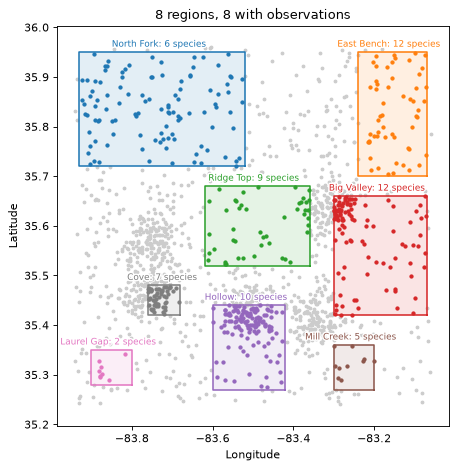

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
samplesar.plot.islands(islands, ax=ax);

## The island curve

Each region's area is its own, on the ellipsoid, and its species are those observed inside it.

In [5]:
fit = islands.fit("power")
fit.params, float(round(fit.r_squared, 3))

({'c': 2.3230104005585237, 'z': 0.2200252987503114}, 0.307)

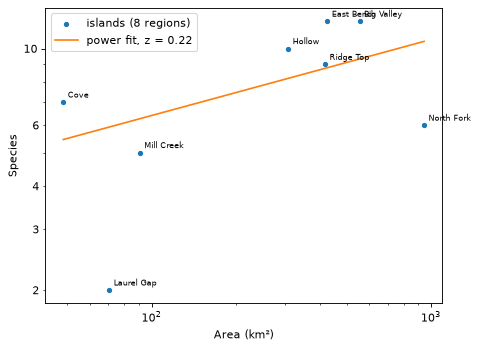

In [6]:
ax = samplesar.plot.curve(islands)
for row in table.itertuples():
    ax.annotate(row.region, (row.area, row.species), fontsize=7, xytext=(4, 4), textcoords="offset points")

## Effort

A region that was visited more has more species recorded, whatever its area. The table carries each region's observations so that effort can be checked before the curve is believed. With only eight regions the comparison is rough, but here the number of observations tracks species about as closely as area does:

In [7]:
table[["area", "n_observations", "species"]].corr(method="spearman").round(2)

,area,n_observations,species
area,1.00,0.45,0.49
n_observations,0.45,1.00,0.63
species,0.49,0.63,1.00


Regions without observations are left out of fits by default: in observation data an empty region is more often unvisited than without species. `min_observations` raises that bar.

In [8]:
islands.sar_data(min_observations=50)

,area,species
0,945.356419,6
1,426.114707,12
2,418.249574,9
3,555.393177,12
4,308.577010,10
5,48.348261,7


## Building a design by hand

A design doesn't have to be every unit of something. Regions are a plain mapping of name to polygon, so you pick which go in and combine sources. `areas` replaces a region's measured area with one you know, and `units` adds rows you give outright (a name, its area in km², its species count) with no boundary or observations behind them.

In [9]:
by_hand = samplesar.designs.islands(
    sample,
    {name: parks[name] for name in ("North Fork", "Ridge Top", "Hollow")},   # a subset
    areas={"Ridge Top": 400.0},                                  # a known area, not the outline's
    units={"Far Ridge": (1200.0, 14), "Old Mill": (25.0, 3)},    # typed in: km², species
)
by_hand = by_hand.add({"Cove": parks["Cove"]})                   # one more region, from anywhere
by_hand.to_frame()

,region,area,species,n_points,n_observations,source,region_area
0,North Fork,945.356419,6,108,119,measured,945.356419
1,Ridge Top,400.000000,9,46,61,area given,418.249574
2,Hollow,308.577010,10,133,399,measured,308.577010
3,Cove,48.348261,7,53,118,measured,48.348261
4,Far Ridge,1200.000000,14,<NA>,<NA>,given,NaN
5,Old Mill,25.000000,3,<NA>,<NA>,given,NaN


The `source` column says where each row's numbers come from. Rows given by hand have no observation counts and are always kept in fits. `select` and `drop` trim a design.

In [10]:
float(round(by_hand.fit("power").params["z"], 3)), by_hand.drop(["Old Mill"]).names

(0.212, ['North Fork', 'Ridge Top', 'Hollow', 'Cove', 'Far Ridge'])

A design can be units alone, with no sample at all, when all you have is a table from a paper:

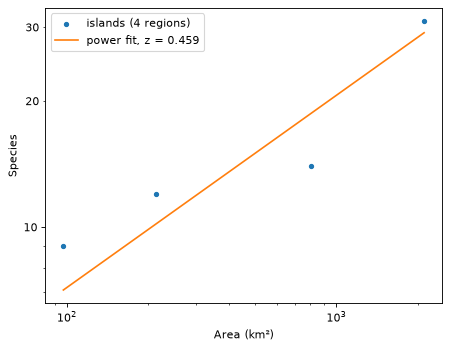

In [11]:
from_a_table = samplesar.designs.islands(
    units={"Site A": (2114, 31), "Site B": (806, 14), "Site C": (214, 12), "Site D": (97, 9)}
)
samplesar.plot.curve(from_a_table);

## Against a nest of the same observations

The two designs answer different questions. A nest's steps share their points and its areas come from the observations; regions are separate units with areas of their own. Their curves aren't comparable point for point.

In [12]:
nest = samplesar.strategies.hull_peel(sample)
float(round(fit.params["z"], 3)), float(round(nest.fit("power").params["z"], 3))   # islands, nested

(0.22, 0.438)

## Nesting within a region

`sample_of` gives one region's observations, with areas measured within the region, ready for any strategy. Here each of the eight regions is nested on its own.

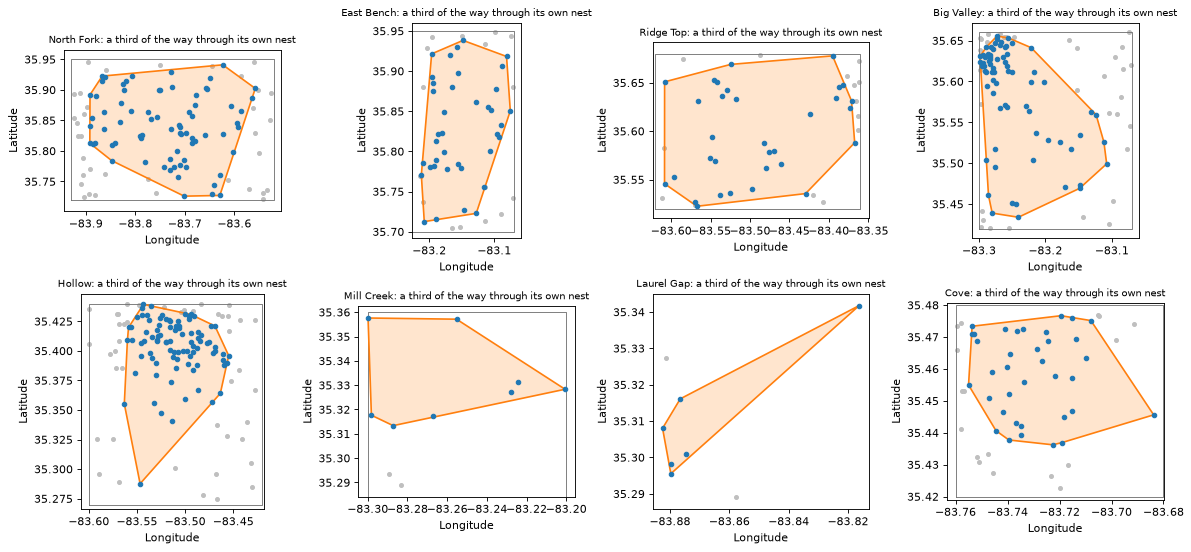

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, name in zip(axes.flat, parks):
    own = islands.sample_of(name)            # this region's observations, masked to it
    nest = samplesar.strategies.hull_random(own, seed=0)
    samplesar.plot.nest(nest, step=nest.n_steps // 3, ax=ax)
    ax.set_title(f"{name}: a third of the way through its own nest", fontsize=9)
fig.tight_layout()

## Real regions

```python
states = samplesar.regions.admin_units("USA", level=1)                 # every state
three = samplesar.regions.admin_units("USA", names=["Alabama", "Georgia", "Texas"])
tennessee = samplesar.regions.admin("USA", 1, "Tennessee")
counties = samplesar.regions.admin_units("USA", 2, inside=tennessee)    # Tennessee's counties
parks = samplesar.regions.read_units("protected_areas.gpkg", "UNIT_NAME")

usa = samplesar.regions.admin("USA")
islands = samplesar.designs.islands(sample, counties, mask=usa)         # areas on land only
```

Boundaries from geoBoundaries are downloaded once and cached; they carry their own licenses and need attribution when published.